
--- Processing: 100% Glycerol ---
Calculated True Period: 0.5850 time units
Initial Amplitude (A): 11.9804 V
Decay Factor (T_2):     15.6612
Baseline Offset (C):   0.2997 V


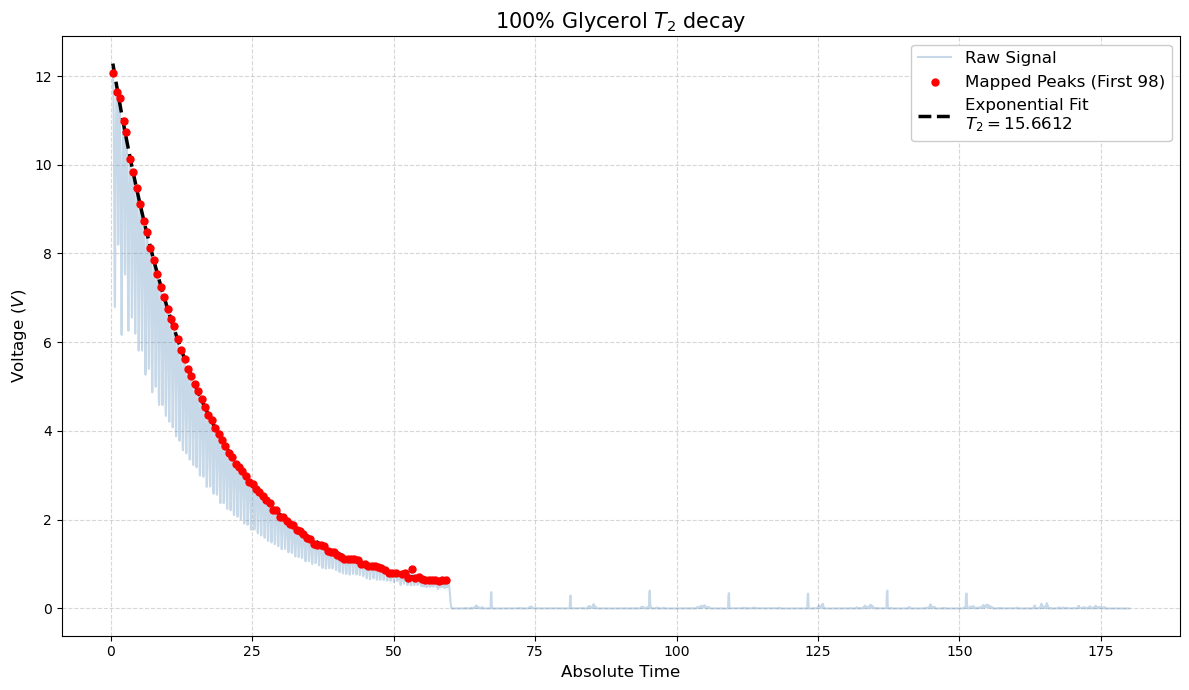


--- Processing: 90% Glycerol ---
Calculated True Period: 1.4029 time units
Initial Amplitude (A): 9.8360 V
Decay Factor (T_2):     48.8253
Baseline Offset (C):   -0.2833 V


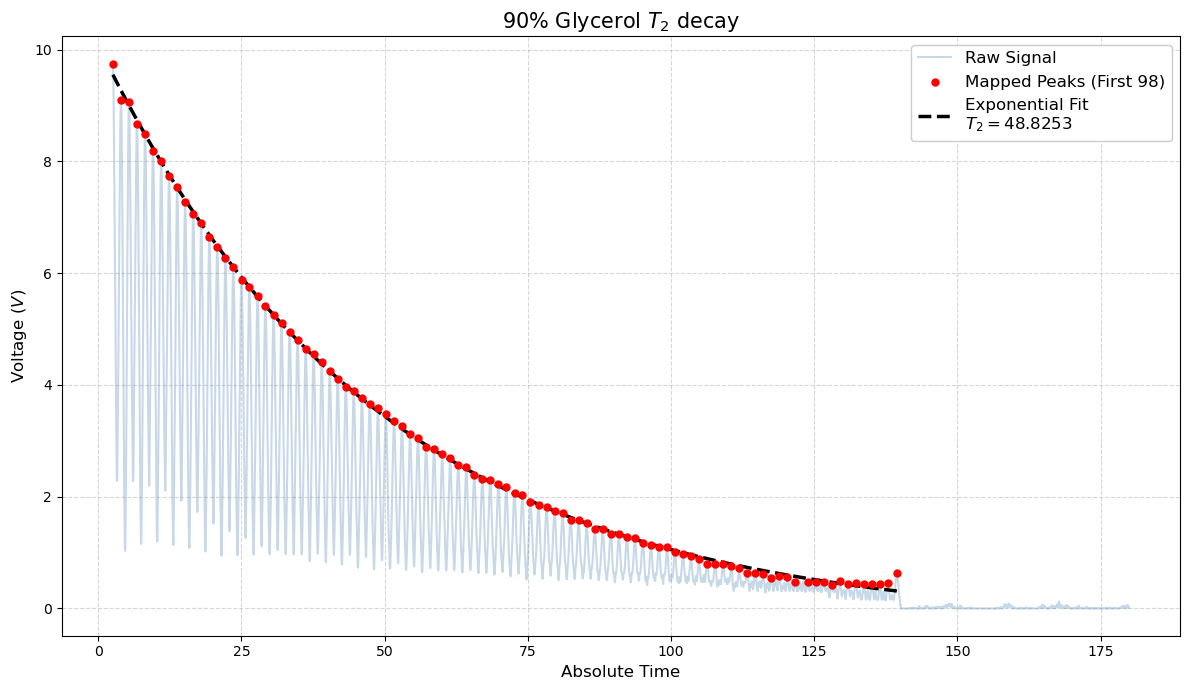


--- Processing: 75% Glycerol ---
Calculated True Period: 1.3926 time units
Initial Amplitude (A): 12.1323 V
Decay Factor (T_2):     92.4417
Baseline Offset (C):   0.1228 V


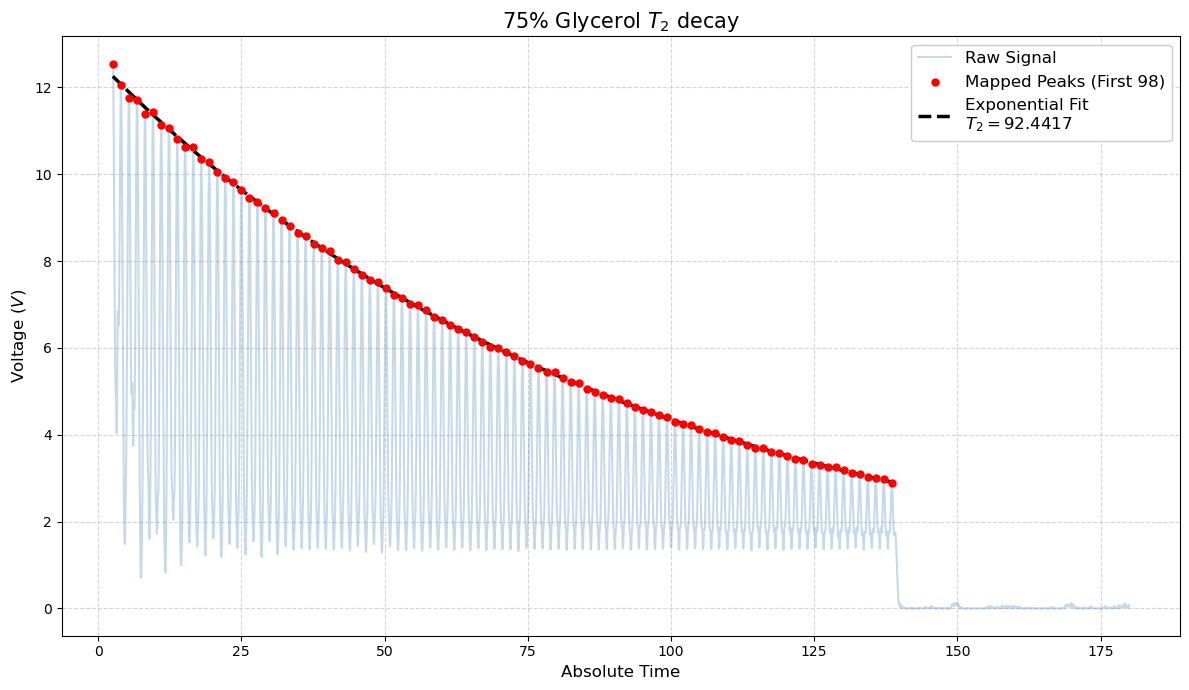


--- Processing: 50% Glycerol ---
Calculated True Period: 0.0029 time units
Initial Amplitude (A): 4.7165 V
Decay Factor (T_2):     0.1571
Baseline Offset (C):   -0.7610 V


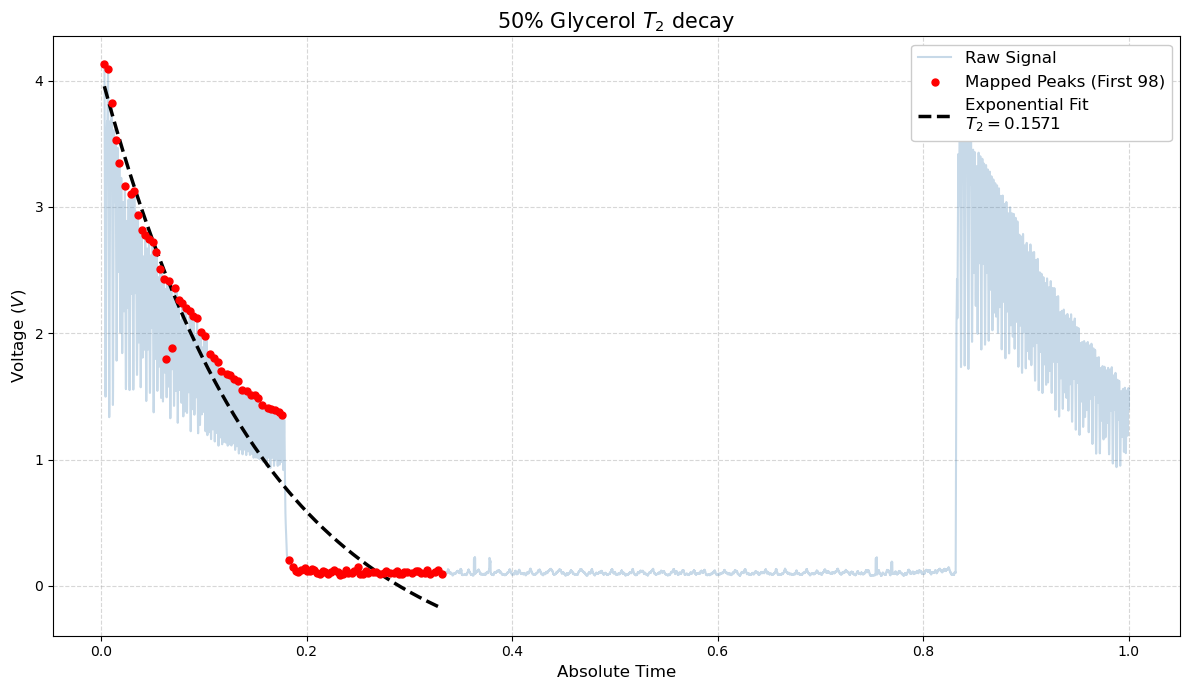


--- Processing: 25% Glycerol ---
Calculated True Period: 4.6438 time units
Initial Amplitude (A): 2.5166 V
Decay Factor (T_2):     156.9979
Baseline Offset (C):   -0.5453 V


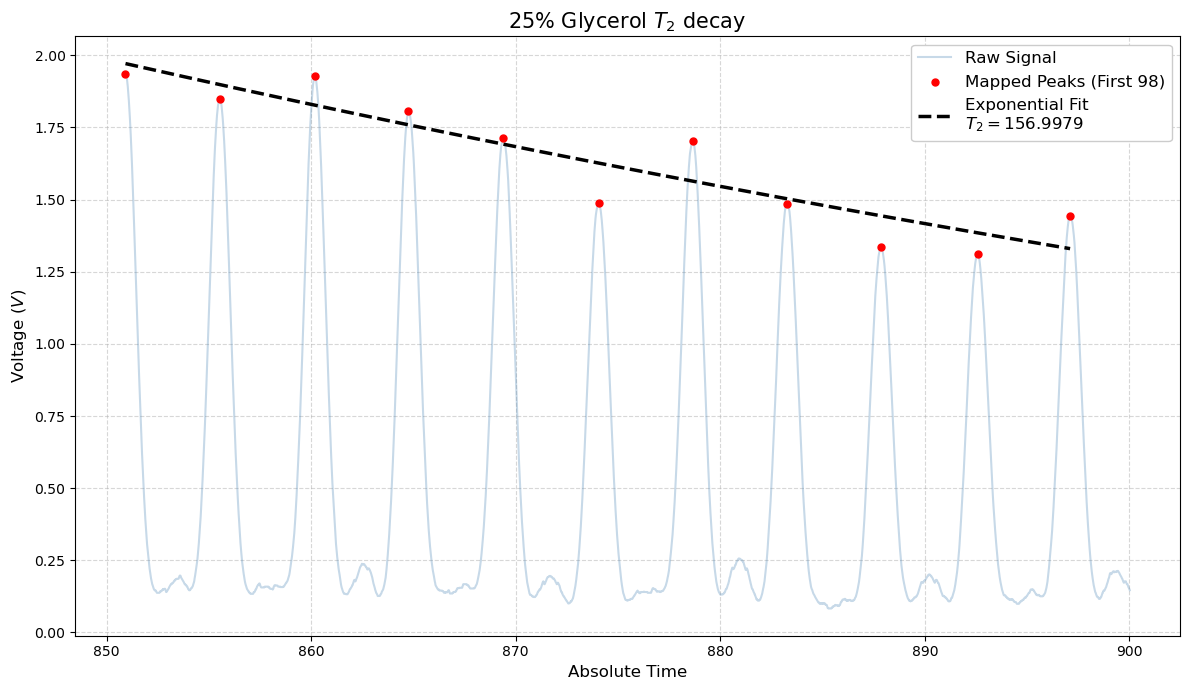

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_data(file_path, sample_name, num_maxima=98):
    """
    Reads T2 NMR/MRI CSV data, maps a specific number of maxima, fits an 
    exponential decay, and plots the results.
    """
    print(f"\n--- Processing: {sample_name} ---")
    
    # 1. Load the file and clean columns
    try:
        data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1)
    except FileNotFoundError:
        print(f"Error: Could not find {file_path}")
        return
    
    # Standardize first two columns (assuming time and voltage)
    data = data.iloc[:, :2] 
    data.columns = ['time', 'voltage']

    # Convert to numeric
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    # 2. Find the global maximum (First Echo) to set the starting point
    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']

    # 3. Estimate period robustly
    post_peak_data = data.loc[vmaxid:].copy()
    
    # Lowered prominence slightly to ensure it catches peaks even in noisier initial data
    min_prominence = post_peak_data['voltage'].max() * 0.15 
    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=10, prominence=min_prominence)
    
    if len(peaks_rough) < 3:
        print("Warning: Could not find enough clear initial peaks to establish a period.")
        return
        
    t_peaks = post_peak_data.iloc[peaks_rough]['time'].values
    period_guess = np.median(np.diff(t_peaks[:5])) # Median is safer than mean if one peak shifts

    print(f"Calculated True Period: {period_guess:.4f} time units")
# 4. Global Peak Find with a "First Group Only" filter
    # Calculate distance between peaks in samples (points)
    points_per_unit = len(data) / (data['time'].max() - data['time'].min())
    min_dist = int(period_guess * points_per_unit * 0.8) # 80% of period to be safe

    # Find peaks across the whole dataset
    # We use a very low height here to catch the whole decay
    all_peaks, props = find_peaks(data['voltage'], distance=min_dist, height=data['voltage'].max()*0.02)
    
    # Filter to only keep peaks that happen AFTER the global maximum
    decay_peaks = all_peaks[all_peaks >= vmaxid]
    
    # --- THE FIX FOR THE 50% SECOND PULSE ---
    # Find the first 'large' gap between peaks. 
    # If a gap is > 2x the period_guess, it means the decay ended and 
    # anything after is a new pulse.
    peak_times = data.loc[decay_peaks, 'time'].values
    peak_voltages = data.loc[decay_peaks, 'voltage'].values
    
    valid_indices = [0]
    for i in range(1, len(peak_times)):
        gap = peak_times[i] - peak_times[i-1]
        if gap > (period_guess * 2.5): # If the gap is too big, stop here
            break
        valid_indices.append(i)
    
    # Slice the results to only include the first continuous decay
    refined_times = peak_times[valid_indices]
    refined_voltages = peak_voltages[valid_indices]

    # Limit by num_maxima if requested
    refined_times = refined_times[:num_maxima]
    refined_voltages = refined_voltages[:num_maxima]

    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})
    
    # 5. Define the mathematical decay function
    def decay_func(t, A, T_2, C):
        return A * np.exp(-t / T_2) + C

    # 6. Prepare data for Curve Fit (Shifted to t=0)
    t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
    v_data = peak_results['Voltage']

    # Initial guesses
    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed.iloc[-1] / 3.0  
    C_guess = v_data.min()
    initial_guess = [A_guess, T2_guess, C_guess]

    try:
        popt, pcov = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess)
        A_fit, T2_fit, C_fit = popt
        
        print(f"Initial Amplitude (A): {A_fit:.4f} V")
        print(f"Decay Factor (T_2):     {T2_fit:.4f}")
        print(f"Baseline Offset (C):   {C_fit:.4f} V")
        
    except RuntimeError:
        print("Error: Curve fit failed to converge. The data might be too noisy.")
        return

    # Generate smooth fit line
    t_smooth_zeroed = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_fit_smooth = decay_func(t_smooth_zeroed, A_fit, T2_fit, C_fit)
    t_smooth_absolute = t_smooth_zeroed + peak_results['Time'].iloc[0]

    # --- 7. Plotting ---
    plt.figure(figsize=(12, 7))

    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], 
             color='steelblue', alpha=0.3, label='Raw Signal')

    plt.scatter(peak_results['Time'], peak_results['Voltage'], 
                color='red', s=25, label=f'Mapped Peaks (First {num_maxima})', zorder=5)

    plt.plot(t_smooth_absolute, v_fit_smooth, 'k--', linewidth=2.5, 
             label=f'Exponential Fit\n$T_2 = {T2_fit:.4f}$')

    plt.title(f'{sample_name} $T_2$ decay', fontsize=15)
    plt.xlabel('Absolute Time', fontsize=12)
    plt.ylabel('Voltage ($V$)', fontsize=12)
    plt.legend(fontsize=12, loc='upper right', framealpha=1.0)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==========================================
# HOW TO USE THE FUNCTION
# ==========================================

# Example 1: Your 75% Glycerol file
file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_2 csv 1.csv"
analyze_t2_data(file_path=file_75, sample_name="100% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\90% glycerol\T290.csv"
analyze_t2_data(file_path=file_75, sample_name="90% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\75% glycerol\T275.csv"
analyze_t2_data(file_path=file_75, sample_name="75% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T2.csv"
analyze_t2_data(file_path=file_75, sample_name="50% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\25% Glyerol\T2.csv"
analyze_t2_data(file_path=file_75, sample_name="25% Glycerol", num_maxima=98)


# Example 2: Just change the variables for the next file!
# file_50 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\50% glycerol\T250.csv"
# analyze_t2_data(file_path=file_50, sample_name="50% Glycerol", num_maxima=98)


--- Processing: 100% Glycerol ---
Calculated True Period: 4.6080
Signal hit noise floor at peak 11. Stopping.
T2: 59.8277, Baseline (C): 0.8105


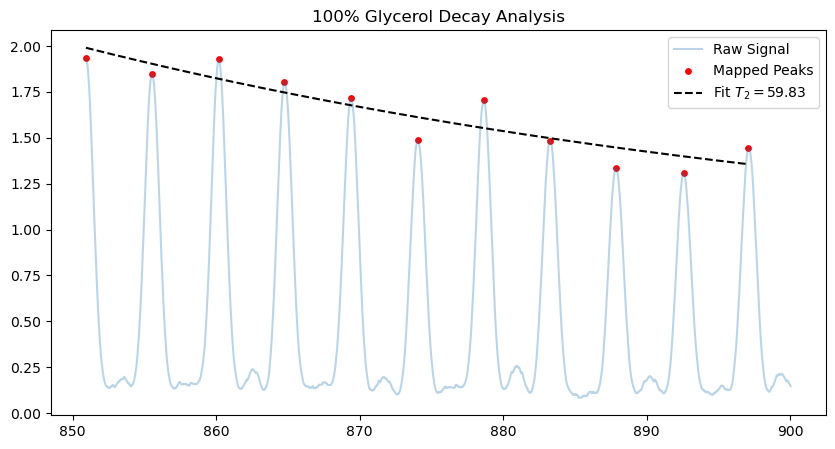


--- Processing: 90% Glycerol ---
Calculated True Period: 1.4003
T2: 45.8798, Baseline (C): -0.0715


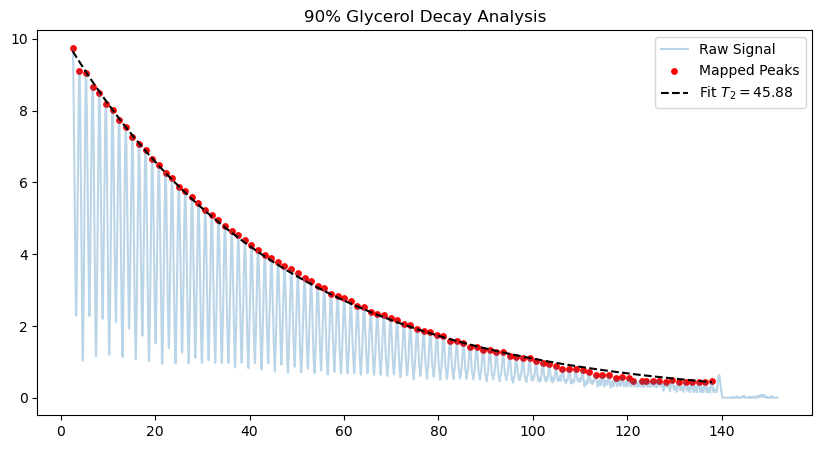


--- Processing: 75% Glycerol ---
Calculated True Period: 1.4003
T2: 60.7905, Baseline (C): 2.3816


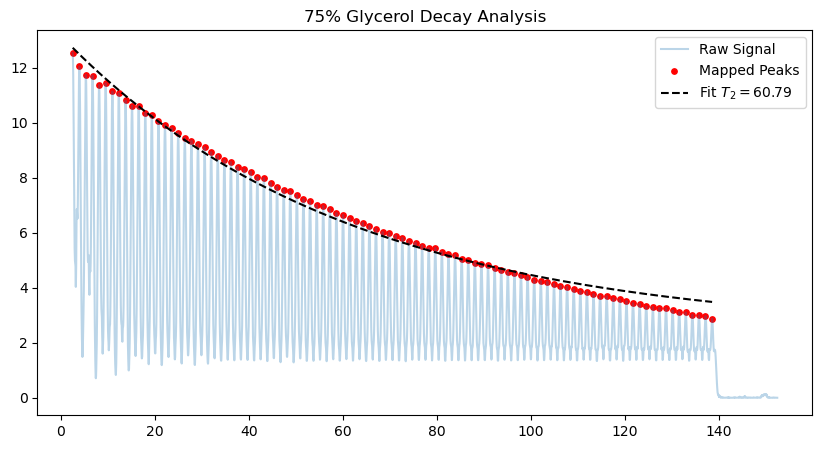


--- Processing: 50% Glycerol ---
Calculated True Period: 0.0018
Signal hit noise floor at peak 56. Stopping.
T2: 0.0513, Baseline (C): 1.6682


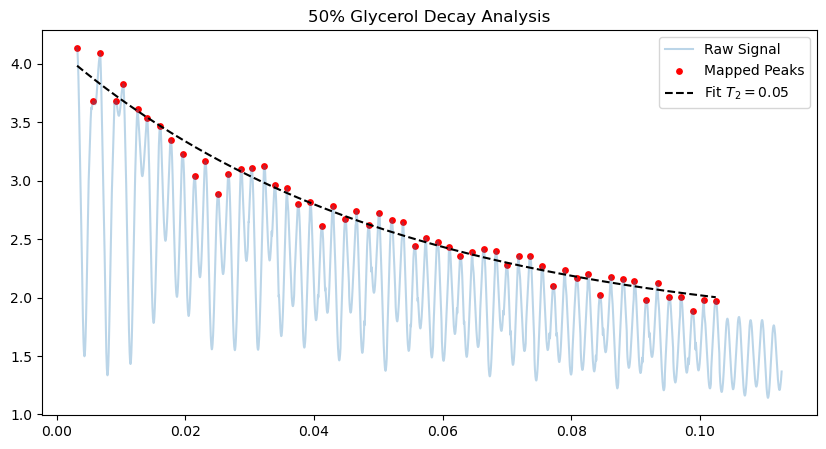


--- Processing: 25% Glycerol ---
Calculated True Period: 4.6080
Signal hit noise floor at peak 11. Stopping.
T2: 59.8277, Baseline (C): 0.8105


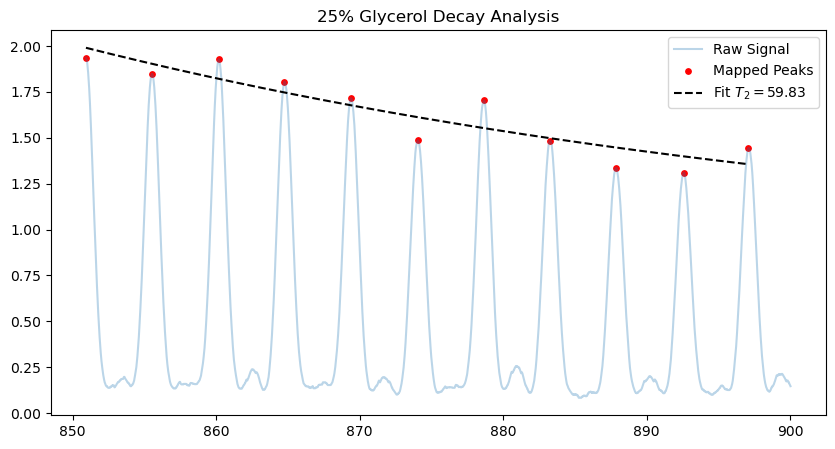

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
def analyze_t2_data(file_path, sample_name, num_maxima=98):
    print(f"\n--- Processing: {sample_name} ---")
    
    # 1. Load and Clean
    try:
        data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1)
    except FileNotFoundError:
        print(f"Error: Could not find {file_path}")
        return
    
    data = data.iloc[:, :2] 
    data.columns = ['time', 'voltage']
    data = data.apply(pd.to_numeric, errors='coerce').dropna().reset_index(drop=True)

    # 2. Find Global Max and establish Period
    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']
    post_peak_data = data.loc[vmaxid:].copy()

    # Initial rough peak find to get the period
    min_prom = post_peak_data['voltage'].max() * 0.1
    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=10, prominence=min_prom)
    
    if len(peaks_rough) < 3:
        print("Warning: Insufficient peaks found.")
        return
        
    t_peaks_initial = post_peak_data.iloc[peaks_rough]['time'].values
    period_guess = np.median(np.diff(t_peaks_initial))
    print(f"Calculated True Period: {period_guess:.4f}")

    # 3. Robust Peak Mapping with Gap Detection
    refined_times = []
    refined_voltages = []
    window_half_width = period_guess * 0.4
    
    # Noise floor estimation for thresholding
    noise_floor = data['voltage'].tail(200).mean()
    noise_std = data['voltage'].tail(200).std()
    stop_threshold = noise_floor + (3 * noise_std) # 3-sigma above noise

    for i in range(num_maxima):
        expected_time = t_start_analysis + (i * period_guess)
        t_start, t_end = expected_time - window_half_width, expected_time + window_half_width
        
        window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
        
        if not window.empty:
            max_idx = window['voltage'].idxmax()
            v_peak = window.loc[max_idx, 'voltage']
            t_peak = window.loc[max_idx, 'time']
            
            # EXIT CONDITION 1: Signal falls into noise
            if v_peak < stop_threshold and i > 5: # allow early peaks to be small if noisy
                print(f"Signal hit noise floor at peak {i}. Stopping.")
                break
            
            # EXIT CONDITION 2: Large timing gap (prevents jumping to later pulses)
            if refined_times and (t_peak - refined_times[-1] > period_guess * 1.8):
                print(f"Large gap detected at t={t_peak:.4f}. Stopping to avoid second pulse.")
                break

            refined_times.append(t_peak)
            refined_voltages.append(v_peak)
        else:
            break

    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})

    # 4. Exponential Fit with Bounds
    def decay_func(t, A, T_2, C):
        return A * np.exp(-t / T_2) + C

    t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
    v_data = peak_results['Voltage']

    # Better initial guesses and strict bounds for 'C' to fix the 75% plot
    initial_guess = [v_data.max() - v_data.min(), t_zeroed.iloc[-1]/2, v_data.min()]
    lower_bounds = [0, 0, v_data.min() - 0.5]
    upper_bounds = [v_data.max() * 2, np.inf, v_data.min() + 0.5]

    try:
        popt, _ = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess, bounds=(lower_bounds, upper_bounds))
        A_fit, T2_fit, C_fit = popt
        print(f"T2: {T2_fit:.4f}, Baseline (C): {C_fit:.4f}")
    except Exception as e:
        print(f"Fit failed: {e}")
        return

    # 5. Plotting (Limited to the analyzed range)
    plt.figure(figsize=(10, 5))
    # Only plot the raw data up to where we actually analyzed
    mask = (data['time'] >= t_start_analysis) & (data['time'] <= peak_results['Time'].max() * 1.1)
    plt.plot(data.loc[mask, 'time'], data.loc[mask, 'voltage'], alpha=0.3, label='Raw Signal')
    
    plt.scatter(peak_results['Time'], peak_results['Voltage'], color='red', s=15, label='Mapped Peaks')
    
    t_smooth = np.linspace(refined_times[0], refined_times[-1], 200)
    plt.plot(t_smooth, decay_func(t_smooth - refined_times[0], A_fit, T2_fit, C_fit), 'k--', label=f'Fit $T_2={T2_fit:.2f}$')
    
    plt.title(f"{sample_name} Decay Analysis")
    plt.legend()
    plt.show()
    file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_2 csv 1.csv"
analyze_t2_data(file_path=file_75, sample_name="100% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\90% glycerol\T290.csv"
analyze_t2_data(file_path=file_75, sample_name="90% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\75% glycerol\T275.csv"
analyze_t2_data(file_path=file_75, sample_name="75% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T2.csv"
analyze_t2_data(file_path=file_75, sample_name="50% Glycerol", num_maxima=98)

file_75 = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\25% Glyerol\T2.csv"
analyze_t2_data(file_path=file_75, sample_name="25% Glycerol", num_maxima=98)


--- Processing: 25% Glycerol ---
Calculated True Period: 0.4736 time units
Initial Amplitude (A): 0.6357 V
Decay Factor (T_2):     36.1107
Baseline Offset (C):   0.6330 V


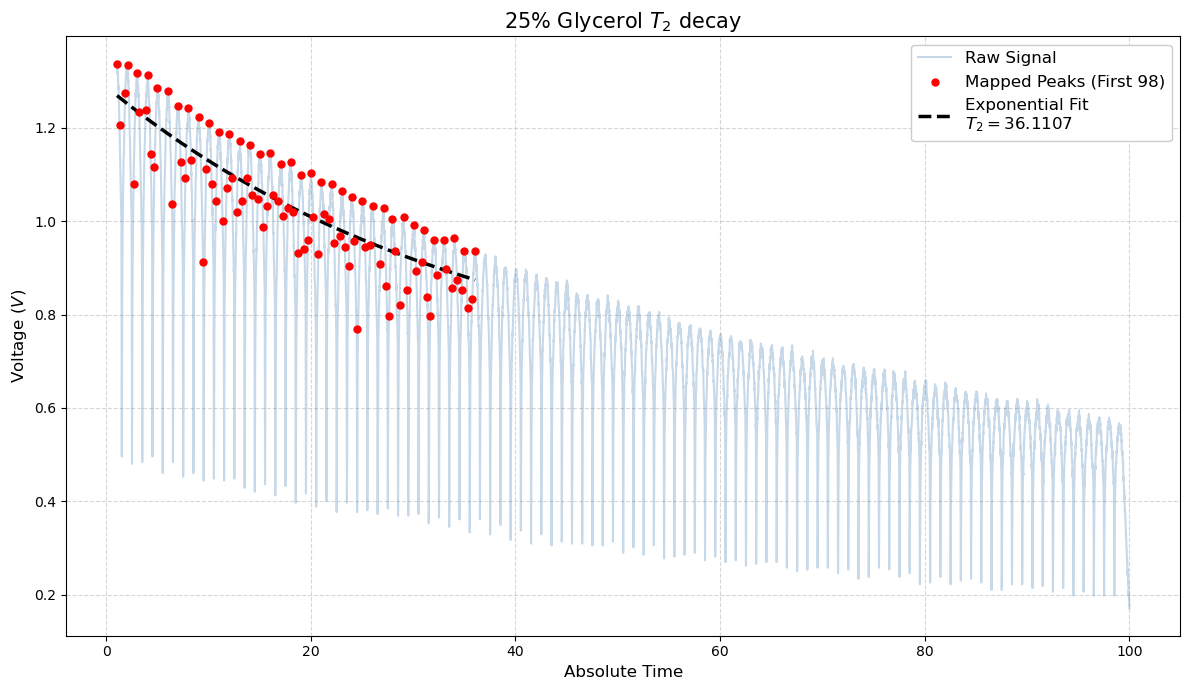

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_data(file_path, sample_name, num_maxima=75):
    """
    Reads T2 NMR/MRI CSV data, maps a specific number of maxima, fits an 
    exponential decay, and plots the results.
    """
    print(f"\n--- Processing: {sample_name} ---")
    
    # 1. Load the file and clean columns
    try:
        data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1)
    except FileNotFoundError:
        print(f"Error: Could not find {file_path}")
        return
    
    # Standardize first two columns (assuming time and voltage)
    data = data.iloc[:, :2] 
    data.columns = ['time', 'voltage']

    # Convert to numeric
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    # 2. Find the global maximum (First Echo) to set the starting point
    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']

    # 3. Estimate period robustly
    post_peak_data = data.loc[vmaxid:].copy()
    
    # Lowered prominence slightly to ensure it catches peaks even in noisier initial data
    min_prominence = post_peak_data['voltage'].max() * 0.2
    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=10, prominence=min_prominence)
    
    if len(peaks_rough) < 3:
        print("Warning: Could not find enough clear initial peaks to establish a period.")
        return
        
    t_peaks = post_peak_data.iloc[peaks_rough]['time'].values
    period_guess = np.median(np.diff(t_peaks[:5])) # Median is safer than mean if one peak shifts

    print(f"Calculated True Period: {period_guess:.4f} time units")
# 4. Global Peak Find with a "First Group Only" filter
    # Calculate distance between peaks in samples (points)
    points_per_unit = len(data) / (data['time'].max() - data['time'].min())
    min_dist = int(period_guess * points_per_unit * 0.5) # 80% of period to be safe

    # Find peaks across the whole dataset
    # We use a very low height here to catch the whole decay
    all_peaks, props = find_peaks(data['voltage'], distance=min_dist, height=data['voltage'].max()*0.02)
    
    # Filter to only keep peaks that happen AFTER the global maximum
    decay_peaks = all_peaks[all_peaks >= vmaxid]
    
    # --- THE FIX FOR THE 50% SECOND PULSE ---
    # Find the first 'large' gap between peaks. 
    # If a gap is > 2x the period_guess, it means the decay ended and 
    # anything after is a new pulse.
    peak_times = data.loc[decay_peaks, 'time'].values
    peak_voltages = data.loc[decay_peaks, 'voltage'].values
    
    valid_indices = [0]
    for i in range(1, len(peak_times)):
        gap = peak_times[i] - peak_times[i-1]
        if gap > (period_guess * 2.5): # If the gap is too big, stop here
            break
        valid_indices.append(i)
    
    # Slice the results to only include the first continuous decay
    refined_times = peak_times[valid_indices]
    refined_voltages = peak_voltages[valid_indices]

    # Limit by num_maxima if requested
    refined_times = refined_times[:num_maxima]
    refined_voltages = refined_voltages[:num_maxima]

    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})
    
    # 5. Define the mathematical decay function
    def decay_func(t, A, T_2, C):
        return A * np.exp(-t / T_2) + C

    # 6. Prepare data for Curve Fit (Shifted to t=0)
    t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
    v_data = peak_results['Voltage']

    # Initial guesses
    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed.iloc[-1] / 3.0  
    C_guess = v_data.min()
    initial_guess = [A_guess, T2_guess, C_guess]

    try:
        popt, pcov = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess)
        A_fit, T2_fit, C_fit = popt
        
        print(f"Initial Amplitude (A): {A_fit:.4f} V")
        print(f"Decay Factor (T_2):     {T2_fit:.4f}")
        print(f"Baseline Offset (C):   {C_fit:.4f} V")
        
    except RuntimeError:
        print("Error: Curve fit failed to converge. The data might be too noisy.")
        return

    # Generate smooth fit line
    t_smooth_zeroed = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_fit_smooth = decay_func(t_smooth_zeroed, A_fit, T2_fit, C_fit)
    t_smooth_absolute = t_smooth_zeroed + peak_results['Time'].iloc[0]

    # --- 7. Plotting ---
    plt.figure(figsize=(12, 7))

    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], 
             color='steelblue', alpha=0.3, label='Raw Signal')

    plt.scatter(peak_results['Time'], peak_results['Voltage'], 
                color='red', s=25, label=f'Mapped Peaks (First {num_maxima})', zorder=5)

    plt.plot(t_smooth_absolute, v_fit_smooth, 'k--', linewidth=2.5, 
             label=f'Exponential Fit\n$T_2 = {T2_fit:.4f}$')

    plt.title(f'{sample_name} $T_2$ decay', fontsize=15)
    plt.xlabel('Absolute Time', fontsize=12)
    plt.ylabel('Voltage ($V$)', fontsize=12)
    plt.legend(fontsize=12, loc='upper right', framealpha=1.0)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

file_75 = r"C:\Users\Student\Downloads\0.5.csv"
analyze_t2_data(file_path=file_75, sample_name="25% Glycerol", num_maxima=98)



--- Processing: 25% Glycerol ---
Calculated True Period: 0.4736 time units
Initial Amplitude (A): 0.7556 V
Decay Factor (T_2):     49.2167
Baseline Offset (C):   0.4950 V


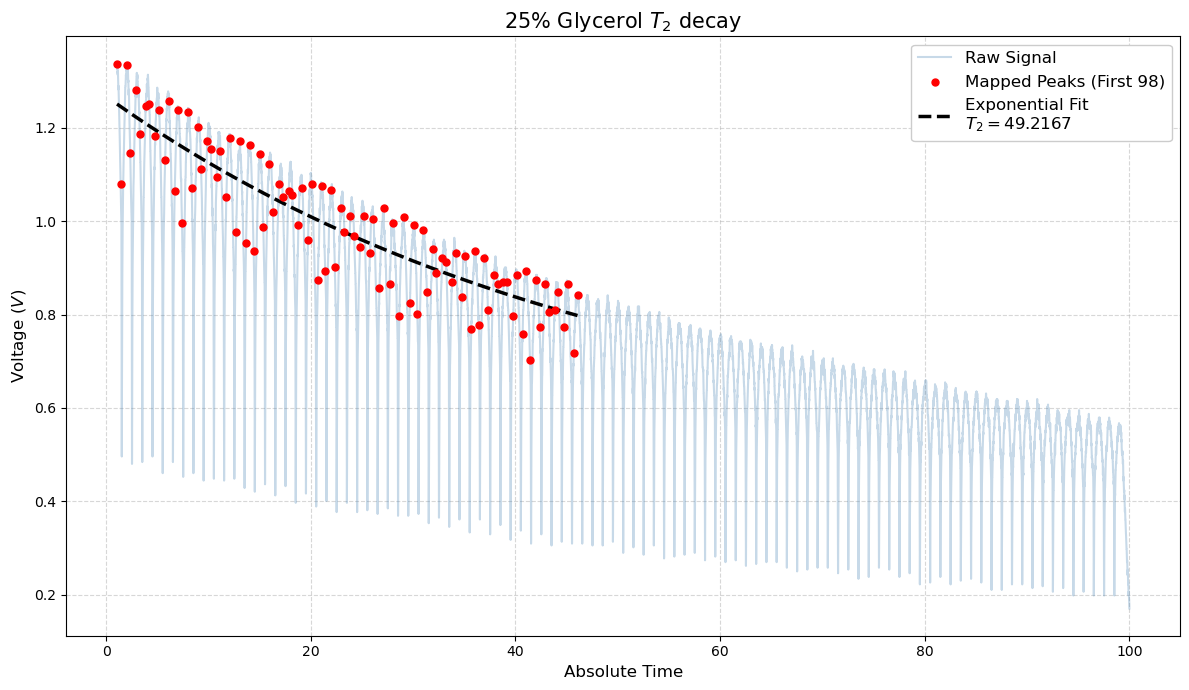

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_data(file_path, sample_name, num_maxima=75):
    """
    Reads T2 NMR/MRI CSV data, maps a specific number of maxima using a 
    sliding window, fits an exponential decay, and plots the results.
    """
    print(f"\n--- Processing: {sample_name} ---")
    
    # 1. Load the file and clean columns
    try:
        data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1)
    except FileNotFoundError:
        print(f"Error: Could not find {file_path}")
        return
    
    # Standardize first two columns (assuming time and voltage)
    data = data.iloc[:, :2] 
    data.columns = ['time', 'voltage']

    # Convert to numeric
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    # 2. Find the global maximum (First Echo) to set the starting point
    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']

    # 3. Estimate period robustly
    post_peak_data = data.loc[vmaxid:].copy()
    
    # Lowered prominence slightly to ensure it catches peaks even in noisier initial data
    min_prominence = post_peak_data['voltage'].max() * 0.2
    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=10, prominence=min_prominence)
    
    if len(peaks_rough) < 3:
        print("Warning: Could not find enough clear initial peaks to establish a period.")
        return
        
    t_peaks = post_peak_data.iloc[peaks_rough]['time'].values
    period_guess = np.median(np.diff(t_peaks[:5])) # Median is safer than mean if one peak shifts

    print(f"Calculated True Period: {period_guess:.4f} time units")

    # 4. Windowed Peak Search (Replaces global find_peaks to fix phase drift)
    points_per_unit = len(data) / (data['time'].max() - data['time'].min())
    
    # Search window width: 50% of the period ensures we look only near the expected peak
    window_size_points = int(period_guess * points_per_unit * 0.5) 
    
    refined_times = []
    refined_voltages = []
    
    # Start from the global maximum found in step 2
    current_idx = vmaxid
    
    for _ in range(num_maxima):
        # Define search bounds around the expected peak location
        search_start = max(0, int(current_idx - window_size_points // 2))
        search_end = min(len(data), int(current_idx + window_size_points // 2))
        
        window = data.iloc[search_start:search_end]
        if window.empty: 
            break
        
        # The true peak is the absolute maximum within this localized window
        max_in_window_idx = window['voltage'].idxmax()
        
        refined_times.append(data.loc[max_in_window_idx, 'time'])
        refined_voltages.append(data.loc[max_in_window_idx, 'voltage'])
        
        # Self-correct: Anchor the next jump from the *actual* peak we just found
        next_expected_time = data.loc[max_in_window_idx, 'time'] + period_guess
        
        # Find the row index in 'data' closest to that next expected time
        current_idx = (data['time'] - next_expected_time).abs().idxmin()

    # Limit to num_maxima just to be safe
    refined_times = np.array(refined_times)[:num_maxima]
    refined_voltages = np.array(refined_voltages)[:num_maxima]
    
    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})
    
    # 5. Define the mathematical decay function
    def decay_func(t, A, T_2, C):
        return A * np.exp(-t / T_2) + C

    # 6. Prepare data for Curve Fit (Shifted to t=0)
    t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
    v_data = peak_results['Voltage']

    # Initial guesses
    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed.iloc[-1] / 3.0  
    C_guess = v_data.min()
    initial_guess = [A_guess, T2_guess, C_guess]

    try:
        popt, pcov = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess)
        A_fit, T2_fit, C_fit = popt
        
        print(f"Initial Amplitude (A): {A_fit:.4f} V")
        print(f"Decay Factor (T_2):     {T2_fit:.4f}")
        print(f"Baseline Offset (C):   {C_fit:.4f} V")
        
    except RuntimeError:
        print("Error: Curve fit failed to converge. The data might be too noisy.")
        return

    # Generate smooth fit line
    t_smooth_zeroed = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_fit_smooth = decay_func(t_smooth_zeroed, A_fit, T2_fit, C_fit)
    t_smooth_absolute = t_smooth_zeroed + peak_results['Time'].iloc[0]

    # --- 7. Plotting ---
    plt.figure(figsize=(12, 7))

    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], 
             color='steelblue', alpha=0.3, label='Raw Signal')

    plt.scatter(peak_results['Time'], peak_results['Voltage'], 
                color='red', s=25, label=f'Mapped Peaks (First {len(refined_times)})', zorder=5)

    plt.plot(t_smooth_absolute, v_fit_smooth, 'k--', linewidth=2.5, 
             label=f'Exponential Fit\n$T_2 = {T2_fit:.4f}$')

    plt.title(f'{sample_name} $T_2$ decay', fontsize=15)
    plt.xlabel('Absolute Time', fontsize=12)
    plt.ylabel('Voltage ($V$)', fontsize=12)
    plt.legend(fontsize=12, loc='upper right', framealpha=1.0)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Run the function
file_75 = r"C:\Users\Student\Downloads\0.5.csv"
analyze_t2_data(file_path=file_75, sample_name="25% Glycerol", num_maxima=98)


--- Processing: 25% Glycerol ---
Using Expected Period: 2.0 time units
Initial Amplitude (A): 652.5294 V
Decay Factor (T_2):     76432.5590
Baseline Offset (C):   -651.2579 V


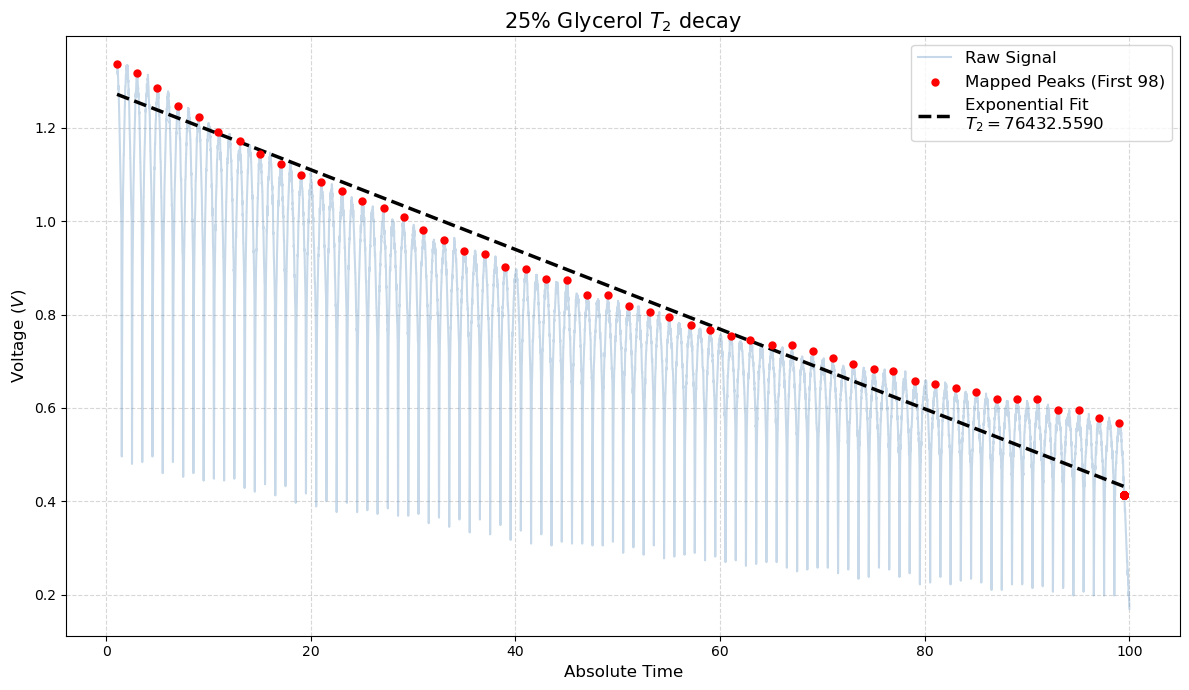

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_data(file_path, sample_name, num_maxima=98, expected_period=2.0):
    """
    Reads T2 NMR/MRI CSV data, maps maxima using a sliding window based on 
    a known expected period, fits an exponential decay, and plots.
    """
    print(f"\n--- Processing: {sample_name} ---")
    
    # 1. Load the file and clean columns
    try:
        data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1)
    except FileNotFoundError:
        print(f"Error: Could not find {file_path}")
        return
    
    data = data.iloc[:, :2] 
    data.columns = ['time', 'voltage']
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    # 2. Find the global maximum (First Echo) to set the starting point
    vmaxid = data['voltage'].idxmax()
    
    # 3. Use the user-provided expected period!
    # No more guessing. If you know the TE (echo time), put it here.
    period_guess = expected_period
    print(f"Using Expected Period: {period_guess} time units")

    # 4. Windowed Peak Search 
    points_per_unit = len(data) / (data['time'].max() - data['time'].min())
    
    # Search window width: 50% of the period
    window_size_points = int(period_guess * points_per_unit * 0.5) 
    
    refined_times = []
    refined_voltages = []
    
    current_idx = vmaxid
    
    for _ in range(num_maxima):
        search_start = max(0, int(current_idx - window_size_points // 2))
        search_end = min(len(data), int(current_idx + window_size_points // 2))
        
        window = data.iloc[search_start:search_end]
        if window.empty: 
            break
        
        # Find absolute max in this window
        max_in_window_idx = window['voltage'].idxmax()
        
        refined_times.append(data.loc[max_in_window_idx, 'time'])
        refined_voltages.append(data.loc[max_in_window_idx, 'voltage'])
        
        # Jump forward by the expected period
        next_expected_time = data.loc[max_in_window_idx, 'time'] + period_guess
        current_idx = (data['time'] - next_expected_time).abs().idxmin()

    refined_times = np.array(refined_times)[:num_maxima]
    refined_voltages = np.array(refined_voltages)[:num_maxima]
    
    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})
    
    # 5. Define decay function
    def decay_func(t, A, T_2, C):
        return A * np.exp(-t / T_2) + C

    # 6. Fit Curve
    t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
    v_data = peak_results['Voltage']

    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed.iloc[-1] / 3.0  
    C_guess = v_data.min()
    initial_guess = [A_guess, T2_guess, C_guess]

    try:
        popt, pcov = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess)
        A_fit, T2_fit, C_fit = popt
        
        print(f"Initial Amplitude (A): {A_fit:.4f} V")
        print(f"Decay Factor (T_2):     {T2_fit:.4f}")
        print(f"Baseline Offset (C):   {C_fit:.4f} V")
        
    except RuntimeError:
        print("Error: Curve fit failed to converge.")
        return

    # 7. Plotting
    t_smooth_zeroed = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_fit_smooth = decay_func(t_smooth_zeroed, A_fit, T2_fit, C_fit)
    t_smooth_absolute = t_smooth_zeroed + peak_results['Time'].iloc[0]

    plt.figure(figsize=(12, 7))
    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], color='steelblue', alpha=0.3, label='Raw Signal')
    plt.scatter(peak_results['Time'], peak_results['Voltage'], color='red', s=25, label=f'Mapped Peaks (First {len(refined_times)})', zorder=5)
    plt.plot(t_smooth_absolute, v_fit_smooth, 'k--', linewidth=2.5, label=f'Exponential Fit\n$T_2 = {T2_fit:.4f}$')
    plt.title(f'{sample_name} $T_2$ decay', fontsize=15)
    plt.xlabel('Absolute Time', fontsize=12)
    plt.ylabel('Voltage ($V$)', fontsize=12)
    plt.legend(fontsize=12, loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- IMPORTANT: Change expected_period to your actual Echo Time! ---
file_75 = r"C:\Users\Student\Downloads\0.5.csv"
analyze_t2_data(file_path=file_75, sample_name="25% Glycerol", num_maxima=98, expected_period=2.0)